# Week 04 ? Task 03: Part-to-whole legality and ranking

This notebook tests whether three datasets legally support a part-to-whole display, creates the required pie and sorted-bar stimuli, and provides a real-reader response workflow. Reader times and rankings are not invented: run the response cell with an actual reader.

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path.cwd()
if not (DATA / "shares_eight.csv").exists():
    DATA = Path(r"D:\University\ML Lab\Week04")
OUTPUT = DATA
plt.style.use("seaborn-v0_8-whitegrid")

## 1. The three part-to-whole conditions

The tests are: (1) parts are exclusive, (2) the whole is meaningful, and (3) the share is the actual question. `exclusivity_check()` is the code test for the first condition; the other two are explicit analytical arguments.

In [2]:
def exclusivity_check(table, columns):
    """Return overlap and coverage facts for boolean part columns."""
    values = table[columns].astype(bool)
    touches_per_row = values.sum(axis=1)
    return {
        "rows": len(values),
        "rows_with_multiple_parts": int((touches_per_row > 1).sum()),
        "rows_with_no_part": int((touches_per_row == 0).sum()),
        "exclusive": bool((touches_per_row <= 1).all()),
    }

channel = pd.read_csv(DATA / "case08_channel_attrib.csv")
touch_cols = ["touch_search", "touch_social", "touch_email", "touch_direct"]
channel_test = exclusivity_check(channel, touch_cols)
channel_shares = channel[touch_cols].mean() * 100
print("Channel exclusivity:", channel_test)
print("Channel touch percentages sum:", channel_shares.sum())

Channel exclusivity: {'rows': 4000, 'rows_with_multiple_parts': 1105, 'rows_with_no_part': 0, 'exclusive': False}
Channel touch percentages sum: 130.975


In [3]:
shares = pd.read_csv(DATA / "shares_eight.csv")
shares_total = shares["share_pct"].sum()
shares_exclusive = shares["subcategory"].is_unique and shares["slice"].is_unique
print("Eight-share rows:", len(shares), "sum:", shares_total, "exclusive labels:", shares_exclusive)
assert abs(shares_total - 100) < 1e-6

q = pd.read_csv(DATA / "case09_premium_share.csv")
q4 = q.loc[q["quarter"].eq("2025Q4")].iloc[0]
premium = q4["premium_revenue_pkr_m"]
other = q4["total_revenue_pkr_m"] - premium
print("2025Q4 premium:", premium, "other:", other, "total:", premium + other)
assert abs(premium + other - q4["total_revenue_pkr_m"]) < 1e-9

Eight-share rows: 8 sum: 100.0 exclusive labels: True
2025Q4 premium: 228.0 other: 372.0 total: 600.0


### Verdicts

| Table | Exclusive parts | Meaningful whole | Share is the question? | Verdict |
|---|---|---|---|---|
| `touch_*` attribution | **No**: customers can have multiple touches; the exact touch percentages sum to 130.975% | Yes: customers are a meaningful whole | **No** for exclusive customer shares; these are overlapping channel reach counts | **Bar chart, not pie** |
| Eight rows in `shares_eight.csv` | Yes: one row per named category and shares sum to 100% | Yes: the eight categories form a declared whole | Yes, if the question is composition | **Pie or sorted bar** |
| Premium vs other, 2025Q4 | Yes: premium and residual other revenue are disjoint and exhaustive | Yes: total 2025Q4 revenue is meaningful | Yes, if the question is the 2025Q4 revenue mix | **Pie or bar** |

## 2. Create the ranking stimuli

The pie deliberately has no numbers, uses file order, `startangle=90`, and `counterclock=False`. The bar chart uses the same values sorted largest first. Both files are saved as PNGs.

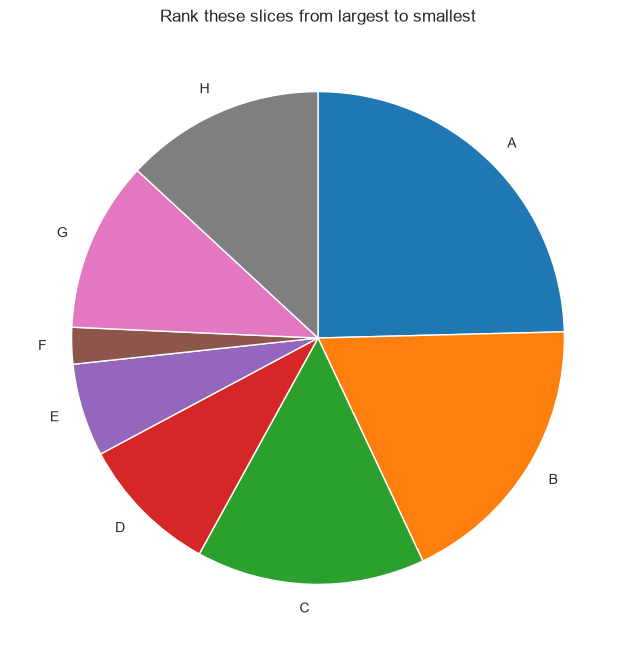

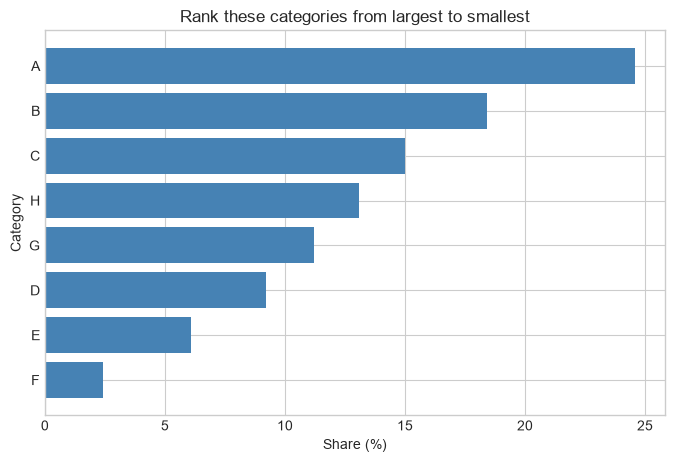

True order: A B C H G D E F
Saved: d:\University\ML Lab\Week04\task03_pie_ranking_stimulus.png
Saved: d:\University\ML Lab\Week04\task03_bar_ranking_stimulus.png


In [4]:
labels = shares["slice"].tolist()
values = shares["share_pct"].to_numpy()
true_order = shares.sort_values("share_pct", ascending=False)["slice"].tolist()

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(values, labels=labels, startangle=90, counterclock=False,
       wedgeprops={"linewidth": 1, "edgecolor": "white"})
ax.set_title("Rank these slices from largest to smallest")
fig.savefig(OUTPUT / "task03_pie_ranking_stimulus.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

bar = shares.sort_values("share_pct", ascending=True)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(bar["slice"], bar["share_pct"], color="steelblue")
ax.set(title="Rank these categories from largest to smallest", xlabel="Share (%)", ylabel="Category")
fig.savefig(OUTPUT / "task03_bar_ranking_stimulus.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print("True order:", " ".join(true_order))
print("Saved:", OUTPUT / "task03_pie_ranking_stimulus.png")
print("Saved:", OUTPUT / "task03_bar_ranking_stimulus.png")

### Real-reader protocol

Show one saved stimulus at a time, without revealing the values. Ask the reader to write A?H from largest to smallest. Start the timer immediately before the reader sees the stimulus and stop it when the order is submitted. The code below accepts the reader?s actual response and appends it to `pie_ranking_results.csv`.

In [5]:
RESULTS = OUTPUT / "pie_ranking_results.csv"
result_columns = ["reader", "stimulus", "order", "seconds"]
if not RESULTS.exists():
    pd.DataFrame(columns=result_columns).to_csv(RESULTS, index=False)
print("Stimuli are ready:", OUTPUT / "task03_pie_ranking_stimulus.png", "and", OUTPUT / "task03_bar_ranking_stimulus.png")
print("Results file:", RESULTS)

Stimuli are ready: d:\University\ML Lab\Week04\task03_pie_ranking_stimulus.png and d:\University\ML Lab\Week04\task03_bar_ranking_stimulus.png
Results file: d:\University\ML Lab\Week04\pie_ranking_results.csv


In [6]:
def record_reader_response(reader, stimulus, order_text, seconds):
    order = order_text.replace(",", " ").upper().split()
    if sorted(order) != sorted(labels) or len(order) != len(labels):
        raise ValueError("Order must contain each of A, B, C, D, E, F, G and H exactly once.")
    row = pd.DataFrame([[reader, stimulus, " ".join(order), float(seconds)]], columns=result_columns)
    row.to_csv(RESULTS, mode="a", header=False, index=False)
    return row

# Example call after timing a real reader; do not replace with invented values:
# record_reader_response("reader-name", "pie", "A B C H D G E F", 12.7)

## 3. Score the real reader

This cell compares recorded orders against the true descending order. It reports the number of misplaced letters and their ranking positions. With no recorded reader, it returns an explicit empty result rather than pretending a study was run.

In [7]:
def score_order(order_text, truth=true_order):
    order = order_text.split()
    wrong_positions = [i + 1 for i, (actual, expected) in enumerate(zip(order, truth)) if actual != expected]
    return len(wrong_positions), wrong_positions

results = pd.read_csv(RESULTS)
if results.empty:
    print("No real-reader responses recorded yet; no timing or error result is claimed.")
else:
    scores = []
    for _, row in results.iterrows():
        errors, positions = score_order(row["order"])
        scores.append({"reader": row["reader"], "stimulus": row["stimulus"],
                       "seconds": row["seconds"], "wrong_letters": errors,
                       "error_positions": " ".join(map(str, positions)) or "none"})
    print(pd.DataFrame(scores).to_string(index=False))

No real-reader responses recorded yet; no timing or error result is claimed.


**Interpretation rule.** One reader can show only that reader?s performance under these instructions; it cannot establish a population effect or confirm the deck?s prediction. The result should be reported plainly, including slow or inconsistent timing and the exact error positions.

## 4. Rule going forward

I will draw a pie only when the parts are exclusive and exhaustive, the whole is meaningful, and the composition is the actual question; otherwise I will use sorted bars.